In [24]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt

In [25]:
# Load dataset (ensure the CSV is placed in the 'data/' directory)
DATA_PATH = '/kaggle/input/datasets/annavictoria/speed-dating-experiment/Speed Dating Data.csv'
df = pd.read_csv(DATA_PATH, encoding='ISO-8859-1')

print(f"Total observations (dates): {len(df)}")
print(f"Unique participants: {df['iid'].nunique()}")

Total observations (dates): 8378
Unique participants: 551


In [26]:
# Data quality overview
data_quality = pd.DataFrame({
    'type': df.dtypes,
    'missing': df.isna().sum(),
    'missing_share_%': (df.isna().mean() * 100).round(2)
})

In [27]:
# 1. Baseline conversion metrics
match_rate = df['match'].mean()
yes_rate = df['dec'].mean()

print(f"Baseline Yes-rate: {yes_rate:.1%}")
print(f"Baseline Match-rate: {match_rate:.1%}")

Baseline Yes-rate: 42.0%
Baseline Match-rate: 16.5%


In [28]:
# Feature selection for core analysis
interaction_cols = ['wave', 'iid', 'pid', 'gender', 'round', 'order', 'dec', 'dec_o', 'match']
participant_profile = ['age', 'race', 'imprace', 'imprelig', 'goal', 'date', 'go_out']
partner_profile = ['age_o', 'race_o', 'samerace', 'int_corr']
ratings_given = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar', 'like', 'prob']
ratings_received = ['attr_o', 'sinc_o', 'intel_o', 'fun_o', 'amb_o', 'shar_o', 'like_o', 'prob_o']
interests = [
    'sports', 'tvsports', 'exercise', 'dining', 'museums', 'art', 'hiking', 
    'gaming', 'clubbing', 'reading', 'tv', 'theater', 'movies', 'concerts', 
    'music', 'shopping', 'yoga'
]

core_cols = (
    interaction_cols + 
    participant_profile + 
    partner_profile + 
    ratings_given + 
    ratings_received + 
    interests
)

clean_df = df[core_cols].copy()
clean_df = clean_df.dropna(subset=['pid', 'dec', 'dec_o', 'match'])
clean_df['pid'] = clean_df['pid'].astype(int)

print(f"Cleaned dataset shape: {clean_df.shape}")

Cleaned dataset shape: (8368, 53)


In [29]:
# Data sanity check: target variable alignment
expected_match = (clean_df['dec'] == 1) & (clean_df['dec_o'] == 1)
mismatches = (clean_df['match'] != expected_match.astype(int)).sum()

if mismatches == 0:
    print("Target variable valid: 'match' strictly equals (dec == 1 and dec_o == 1).")

Target variable valid: 'match' strictly equals (dec == 1 and dec_o == 1).


In [30]:
# Conversion benchmarks by gender (0 = Female, 1 = Male)
gender_benchmarks = clean_df.groupby('gender').agg(
    total_dates=('dec', 'count'),
    yes_rate=('dec', 'mean'),
    incoming_yes_rate=('dec_o', 'mean'),
    match_rate=('match', 'mean')
).rename(index={0: 'Female', 1: 'Male'})

print(gender_benchmarks.round(3))

        total_dates  yes_rate  incoming_yes_rate  match_rate
gender                                                      
Female         4184     0.365              0.475       0.165
Male           4184     0.475              0.365       0.165


In [31]:
def calculate_gini(array):
    """Calculate Gini coefficient to measure attention inequality."""
    array = np.array(array, dtype=np.float64)
    if np.amin(array) < 0:
        array -= np.amin(array)
    array += 0.0000001
    array = np.sort(array)
    index = np.arange(1, array.shape[0] + 1)
    n = array.shape[0]
    return ((np.sum((2 * index - n - 1) * array)) / (n * np.sum(array)))

# Aggregate attention metrics per user
user_metrics = clean_df.groupby(['iid', 'gender']).agg(
    dates_count=('dec', 'count'),
    outgoing_yes=('dec', 'sum'),
    incoming_yes=('dec_o', 'sum'),
    matches=('match', 'sum')
).reset_index()

user_metrics['selectivity'] = user_metrics['outgoing_yes'] / user_metrics['dates_count']
user_metrics['popularity'] = user_metrics['incoming_yes'] / user_metrics['dates_count']

gini_f = calculate_gini(user_metrics[user_metrics['gender'] == 0]['incoming_yes'])
gini_m = calculate_gini(user_metrics[user_metrics['gender'] == 1]['incoming_yes'])

print(f"Attention Gini Coefficient (Female): {gini_f:.3f}")
print(f"Attention Gini Coefficient (Male): {gini_m:.3f}")

Attention Gini Coefficient (Female): 0.335
Attention Gini Coefficient (Male): 0.382


In [32]:
# Selectivity paradox: conversion rate of sent 'Yes' into mutual matches
user_metrics['match_conversion'] = np.where(
    user_metrics['outgoing_yes'] > 0,
    user_metrics['matches'] / user_metrics['outgoing_yes'],
    0.0
)

user_metrics['selectivity_quintile'] = pd.qcut(
    user_metrics['selectivity'], 
    q=5, 
    labels=['Very Selective', 'Selective', 'Moderate', 'Generous', 'Spam-like']
)

selectivity_analysis = user_metrics.groupby(['gender', 'selectivity_quintile'], observed=False).agg(
    users_cnt=('iid', 'count'),
    mean_yes_rate=('selectivity', 'mean'),
    mean_matches=('matches', 'mean'),
    mean_match_conversion=('match_conversion', 'mean')
).reset_index()

selectivity_analysis['gender'] = selectivity_analysis['gender'].map({0: 'Female', 1: 'Male'})
print(selectivity_analysis.round(3))

   gender selectivity_quintile  users_cnt  mean_yes_rate  mean_matches  \
0  Female       Very Selective         81          0.100         0.975   
1  Female            Selective         51          0.287         2.157   
2  Female             Moderate         69          0.436         3.058   
3  Female             Generous         40          0.575         3.975   
4  Female            Spam-like         33          0.806         3.970   
5    Male       Very Selective         41          0.106         0.780   
6    Male            Selective         53          0.282         2.057   
7    Male             Moderate         77          0.440         2.753   
8    Male             Generous         32          0.596         3.281   
9    Male            Spam-like         74          0.828         3.135   

   mean_match_conversion  
0                  0.464  
1                  0.507  
2                  0.469  
3                  0.418  
4                  0.388  
5                  0.40

In [33]:
# H3: Compatibility vs Baseline
# Map empirical base yes-rates back to pairwise interactions
user_p_yes = user_metrics.set_index('iid')['selectivity'].to_dict()
clean_df['p_yes_i'] = clean_df['iid'].map(user_p_yes)
clean_df['p_yes_j'] = clean_df['pid'].map(user_p_yes)

# Expected match rate assuming independence (P(A and B) = P(A) * P(B))
clean_df['expected_match'] = clean_df['p_yes_i'] * clean_df['p_yes_j']

observed_rate = clean_df['match'].mean()
expected_rate = clean_df['expected_match'].mean()
lift = (observed_rate - expected_rate) / expected_rate

print(f"Observed Match Rate: {observed_rate:.4f}")
print(f"Expected Match Rate (Independence Null Model): {expected_rate:.4f}")
print(f"Compatibility Lift: {lift:+.2%}")

Observed Match Rate: 0.1649
Expected Match Rate (Independence Null Model): 0.1697
Compatibility Lift: -2.79%


In [34]:
# Decision Drivers Analysis (Logistic Regression)
ratings = ['attr', 'sinc', 'intel', 'fun', 'amb', 'shar']

def run_driver_analysis(gender_val, gender_label):
    subset = clean_df[clean_df['gender'] == gender_val].dropna(subset=ratings + ['dec'])
    x = sm.add_constant(subset[ratings])
    y = subset['dec']
    
    model = sm.Logit(y, x).fit(disp=False)
    
    odds_ratios = pd.DataFrame({
        'factor': model.params.index,
        'coef': model.params.values,
        'odds_ratio': np.exp(model.params.values),
        'p_value': model.pvalues.values
    }).query("factor != 'const'").sort_values(by='coef', ascending=False)
    
    odds_ratios['gender'] = gender_label
    return odds_ratios

drivers_female = run_driver_analysis(0, 'Female evaluating Male')
drivers_male = run_driver_analysis(1, 'Male evaluating Female')

drivers_summary = pd.concat([drivers_female, drivers_male])
print(drivers_summary.round(3))

  factor   coef  odds_ratio  p_value                  gender
1   attr  0.406       1.501    0.000  Female evaluating Male
6   shar  0.276       1.318    0.000  Female evaluating Male
4    fun  0.274       1.316    0.000  Female evaluating Male
3  intel  0.129       1.138    0.004  Female evaluating Male
2   sinc -0.091       0.913    0.009  Female evaluating Male
5    amb -0.173       0.841    0.000  Female evaluating Male
1   attr  0.682       1.977    0.000  Male evaluating Female
6   shar  0.270       1.310    0.000  Male evaluating Female
4    fun  0.262       1.299    0.000  Male evaluating Female
3  intel -0.037       0.964    0.387  Male evaluating Female
5    amb -0.153       0.858    0.000  Male evaluating Female
2   sinc -0.158       0.853    0.000  Male evaluating Female


<Figure size 1000x500 with 0 Axes>

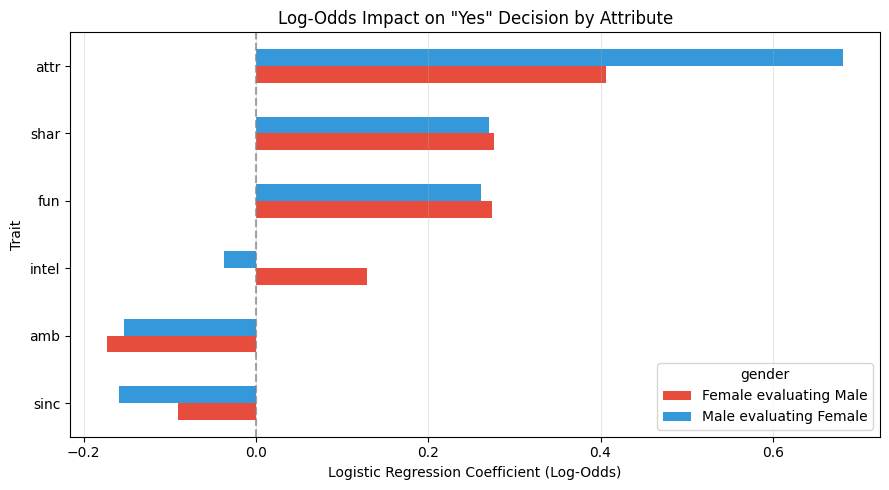

In [35]:
# Visualizing Log-Odds Impact
plt.figure(figsize=(10, 5))
summary_pivot = drivers_summary.pivot(index='factor', columns='gender', values='coef')
summary_pivot.sort_values(by='Male evaluating Female', ascending=True).plot(
    kind='barh', 
    figsize=(9, 5), 
    color=['#e74c3c', '#3498db']
)
plt.title('Log-Odds Impact on "Yes" Decision by Attribute')
plt.xlabel('Logistic Regression Coefficient (Log-Odds)')
plt.ylabel('Trait')
plt.axvline(0, color='gray', linestyle='--', alpha=0.7)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
df['race'].unique()

array([ 4.,  2.,  6.,  3.,  1., nan])